# Your own statistic against your own null

The tests in `spaclone.qc` and `spaclone.tl` are statistics with a null design built in. A new question (a metric from
a paper, a step of your own pipeline) needs the same two parts written by hand: the **statistic**, a function of the
receptor table, and the **null design**, which says what random data sets look like. `spaclone.nulls` provides both
designs and the engine:

* `nulls.Permute(columns, within=..., blocks=...)`: *random labelling*. Values of some columns (clone, isotype,
  mutated) are exchanged between rows; positions stay where they are.
* `nulls.Relocate(slots, unit=..., within=..., window_um=..., weights=..., replace=...)`: *random placement*. Whole
  units (all rows of a spot, bead or cell, with every other column, read counts included) move to random slots.
* `nulls.placebo(statistic, data, design)` re-runs the statistic on many random data sets;
  `nulls.compare_designs` does it for several designs at once.

Three decisions decide what such a test can conclude: what the statistic contains, what the null keeps fixed, and how
many random data sets there are. We go through them on two data sets used in `02_is_my_data_spatial`: an AIR-SPACE
lymph node (here the uninfected Mock node, built into `spaclone.datasets`) and the Stereo-XCR-seq LUAD chip D06047A2.

In [1]:
import time

t_start = time.time()

import warnings
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

import spaclone
from spaclone import gex, io, nulls, pl, pp

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 100
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"  # one-line warnings
print("spaclone", spaclone.__version__)

spaclone 1.0.0


## The data

`spaclone.datasets.airspace("Mock")` downloads the Mock node from GEO GSE286452 once (bead counts and clone table,
about 69 MB, verified by sha256; needs `pip install "spaclone[datasets]"`); later calls only verify the files. The
LUAD chip is GEO sample GSM9684211 (series GSE328481), file `GSM9684211_D06047A2.h5ad` (0.98 GB): download it and put
it next to this notebook or set the environment variable `SPACLONE_LUAD_H5AD` to its path.

For each data set we keep the IGH records on tissue with a valid junction, and give every unit (bead or cell) its Ig
RNA stratum (`gex.ig_rna`: molecules of Ig constant-region genes in the unit, binned 0, 1–2, 3–9, 10–29, 30–99,
100–299, ≥ 300). The table of all units is what `Relocate` draws its slots from.

In [2]:
LUAD_H5AD = Path(os.environ.get("SPACLONE_LUAD_H5AD", "GSM9684211_D06047A2.h5ad"))  # see "The data"


def units_of(adata, species):
    """Every tissue unit (bead or cell) with its position and Ig RNA stratum: the slots of a placement null."""
    gex.ig_rna(adata, genes=species)
    keep = adata.obs["in_tissue"].to_numpy(bool) if "in_tissue" in adata.obs else np.ones(adata.n_obs, bool)
    return pd.DataFrame({"spot_id": adata.obs_names[keep].astype(str),
                         "x_um": adata.obsm["spatial"][keep, 0], "y_um": adata.obsm["spatial"][keep, 1],
                         "ig_bin": adata.obs["ig_rna_bin"].astype(str).to_numpy()[keep]})


h5ad, clone_table = spaclone.datasets.airspace("Mock")
mock = io.read_airspace(h5ad, clone_table)
slots_mock = units_of(mock.gex, "mouse")
air_mock = pp.filter_records(mock.air, on_tissue=True, loci="IGH").air.merge(slots_mock[["spot_id", "ig_bin"]],
                                                                           on="spot_id")

luad = io.from_cell_calls(LUAD_H5AD, cell_type_key="anno")
slots_luad = units_of(luad.gex, "human")
air_luad = pp.filter_records(luad.air, loci="IGH").air.merge(slots_luad[["spot_id", "ig_bin"]], on="spot_id")

for name, a, s in (("AIR-SPACE Mock", air_mock, slots_mock), ("LUAD D06047A2", air_luad, slots_luad)):
    print(f"{name}: {len(a):,} IGH records on {a.spot_id.nunique():,} of {len(s):,} units, "
          f"{a.clone_id.nunique():,} clones")

AIR-SPACE Mock: 568 IGH records on 428 of 16,642 units, 349 clones
LUAD D06047A2: 6,092 IGH records on 6,092 of 130,469 units, 976 clones


## 1. The statistic is a function of the receptor table

Our statistic asks whether units of one clone sit close together: among all pairs of (unit, clone) records of
clones with 2–50 units, the share closer than 30 µm and the share 30–100 µm apart. It is written as a plain function
of the receptor table, and three rules apply:

1. **It contains the whole pipeline.** The statistic starts from the records that the null design produces and does
   every later step itself: here the collapse of several molecules of one clone on one bead into one unit and the
   clone-size window. A step done once before the placebo (for example removing clones that look dispersed) would be
   missing from the random data sets, and the placebo would be partial and biased.
2. **It is deterministic**, or it takes `rng=` and is run with `placebo(..., pass_rng=True)` (for example a
   statistic that rarefies), so that its own randomness is reproducible and independent of the design's.
3. **It returns a scalar, a 1-D array, a Series or a dict of scalars**: one component each, every component with its
   own p-value, and a family-wise (max-T) p-value over the components.

In [3]:
def same_clone_pairs(a, bands_um=((0, 30), (30, 100)), max_units=50):
    """Share of same-clone (unit, clone) pairs in each distance band, over clones of 2 to max_units units."""
    u = a.drop_duplicates(["spot_id", "clone_id"])  # several molecules of one clone on one bead count once
    size = u["clone_id"].map(u["clone_id"].value_counts())
    u = u[(size >= 2) & (size <= max_units)]
    codes = pd.factorize(u["clone_id"])[0]
    xy = u[["x_um", "y_um"]].to_numpy()
    pairs = cKDTree(xy).query_pairs(max(hi for _, hi in bands_um), output_type="ndarray")
    pairs = pairs[codes[pairs[:, 0]] == codes[pairs[:, 1]]]
    d = np.linalg.norm(xy[pairs[:, 0]] - xy[pairs[:, 1]], axis=1)
    n = np.bincount(codes)
    total = (n * (n - 1) // 2).sum()
    return {f"pairs {lo}-{hi} µm": float(((d >= lo) & (d < hi)).sum() / total) for lo, hi in bands_um}


pd.DataFrame({"AIR-SPACE Mock": same_clone_pairs(air_mock), "LUAD D06047A2": same_clone_pairs(air_luad)})

,AIR-SPACE Mock,LUAD D06047A2
pairs 0-30 µm,0.053232,0.001080
pairs 30-100 µm,0.145754,0.004387


## 2. Null designs, and what one random data set looks like

A design is an object; printing it states what it does, and calling it on a table with a generator returns one random
version of the table. Here clone labels are exchanged among the records of the same Ig RNA stratum:

In [4]:
labels = nulls.Permute("clone_id", within="ig_bin")
print(labels)
shuffled = labels(air_luad, np.random.default_rng(0))
cols = ["spot_id", "x_um", "y_um", "ig_bin", "clone_id"]
pd.concat({"observed": air_luad[cols].head(4), "one random data set": shuffled[cols].head(4)}, axis=1)

Permute(columns=['clone_id'], within=['ig_bin'], blocks=None)


observed                                                   one random data set                                                    
   spot_id    x_um    y_um   ig_bin                 clone_id             spot_id    x_um    y_um   ig_bin                   clone_id
0       43  6904.0  2291.5  100-299     IGH|||CAKDWGTGWLFDYW                  43  6904.0  2291.5  100-299     IGH|||CAKDRGGDYDYGLDVW
1       45  6901.5  2281.5    30-99          IGH|||CARLGPGNW                  45  6901.5  2281.5    30-99  IGH|||CVHFGLCEGGECHWYLRLW
2       47  6897.0  2265.0    30-99   IGH|||CAKNYRFGSGSPLDSW                  47  6897.0  2265.0    30-99          IGH|||CARGRGALDLW
3       48  6895.5  2298.0  100-299  IGH|||CAKSAFSSGYGDYLDHW                  48  6895.5  2298.0  100-299   IGH|||CARDLKISGVATGWLDPW

Positions and strata stay; only the clone labels move, and each stratum keeps its multiset of labels.

A placement design moves units instead. `Relocate` takes the table of slots (every unit of the section, with the
stratum column) and moves every unit, with all its records and all their columns, to a random slot of the same
stratum:

In [5]:
placement = nulls.Relocate(slots_mock, within="ig_bin")
print(placement)
moved = placement(air_mock, np.random.default_rng(0))
cols = ["spot_id", "x_um", "y_um", "ig_bin", "clone_id", "consensus_count", "umi"]
pd.concat({"observed": air_mock[cols].head(4), "one random data set": moved[cols].head(4)}, axis=1)

Relocate(unit='spot_id', within=['ig_bin'], window_um=None, weights=None, replace=False, n_slots=16642, slot_columns=['spot_id', 'x_um', 'y_um'])


observed                                                             one random data set                                                            
          spot_id     x_um      y_um ig_bin clone_id consensus_count      umi             spot_id      x_um     y_um ig_bin clone_id consensus_count      umi
0  GATTACTCCCGGTT  1143.87  1667.185  30-99     2413             1.0  AGAGGGA      AGATTACCCCACCG  1078.350  1608.36  30-99     2413             1.0  AGAGGGA
1  ACAGTCCCAGACCA  1072.24  1484.080  10-29     1524             1.0  GAAGAGT      CTGTAGTCCATTTT  3278.600  2866.50  10-29     1524             1.0  GAAGAGT
2  AGCTACTCCATTTA  2649.40  1784.575  10-29     2509             1.0  CGGGTGT      GACCTAGTTTCGCG  1586.000  1490.45  10-29     2509             1.0  CGGGTGT
3  CACTCACGACGCCG  3400.80  1621.100  10-29     2593             1.0  ACCATGG      TAAATCAACTTAAG  2676.765  1848.86  10-29     2593             1.0  ACCATGG

Position and spot id come from the new slot; clone, read count, UMI and every other column travel with the unit. All
records of one bead move together (the default `unit="spot_id"`), so a bead that held three molecules of one clone
still holds them after the move:

In [6]:
per_bead = lambda t: t.groupby("spot_id").size().value_counts().sort_index()
pd.DataFrame({"observed": per_bead(air_mock), "random data set": per_bead(moved)}).rename_axis("records per bead").head(6)

,observed,random data set
records per bead,,
1,350,350
2,54,54
3,14,14
4,4,4
5,2,2
6,1,1


## 3. One placebo

`nulls.placebo` runs the statistic on the observed table and on `n_perm` random tables. Every random table gets its
own generator spawned from `rng`, so the result is the same for any `n_jobs`.

In [7]:
res = nulls.placebo(same_clone_pairs, air_mock, labels, n_perm=500, rng=0)
print(res)
res.table

TestResult(placebo: observed=[0.05323194 0.14575412], null_mean=[0.00965522 0.0186421 ], p_value=[0.00199601 0.00199601]; table 2×12)


,component,observed,null_mean,null_sd,null_lo,null_hi,ratio,standardised_gap,p_value,p_maxT,mc_se,n_perm
0,pairs 0-30 µm,0.053232,0.009655,0.002094,0.005954,0.013719,5.513280,20.826072,0.001996,0.001996,0.001996,500
1,pairs 30-100 µm,0.145754,0.018642,0.003981,0.011671,0.028007,7.818545,31.999399,0.001996,0.001996,0.001996,500


`observed` is the statistic on the data, `null_mean`, `null_sd` and `null_lo` / `null_hi` (2.5% and 97.5%) describe
the 500 placebo values, `ratio` = observed / null mean, `standardised_gap` = (observed − null median) / null sd,
`p_value` is the Monte-Carlo p-value (1 + #{null ≥ observed}) / (B + 1), `p_maxT` the family-wise p-value over the two
components, and `mc_se` the Monte-Carlo standard error of p. The p-value can never be smaller than 1/501 = 0.002: with
B random data sets, a p-value below 1/(B + 1) is not possible, so choose B for the smallest p-value you need (for
example ≥ 20 × the number of tests for a BH threshold).

The placebo draws are kept in `res.null` (one column per component):

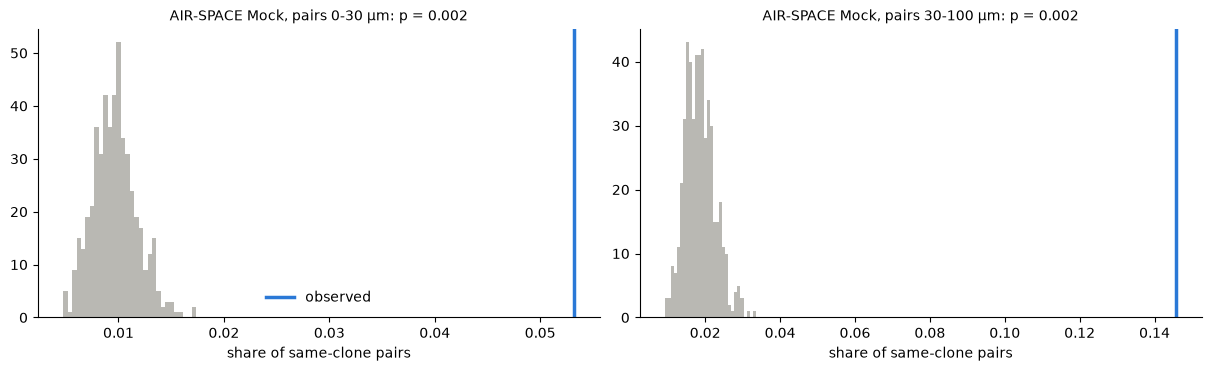

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), layout="constrained")
for ax, (k, row) in zip(axes, res.table.iterrows()):
    ax.hist(res.null[:, k], bins=30, color="#b9b8b3")
    ax.axvline(row.observed, color="#2a78d6", lw=2.5, label="observed")
    ax.set_title(f"AIR-SPACE Mock, {row.component}: p = {row.p_value:.3f}", fontsize=10)
    ax.set_xlabel("share of same-clone pairs")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
plt.show()

## 4. The null must keep the confounders

A confounder is anything that shapes the statistic in the observed data and is not what the test is about. Two matter
for spatial receptor data:

* **Local Ig RNA (depth).** Receptor calls follow the Ig RNA of the unit, in a working assay and in a broken one.
  Plasma cells hold far more Ig RNA than B cells and sit together, and their clones are large. A null that ignores
  depth mixes labels between Ig-rich and Ig-poor units and makes any assay look clonally clustered.
* **Where the units are.** The question here is which clone a unit carries, not where receptor-positive units are.
  A null that moves the units also scatters the units themselves, which in tissue sit in aggregates.

`nulls.compare_designs` runs the same statistic under several designs. We use five:

In [9]:
def designs(slots):
    return {
        "labels, whole sample": nulls.Permute("clone_id"),
        "labels, same Ig RNA": nulls.Permute("clone_id", within="ig_bin"),
        "units moved, same Ig RNA": nulls.Relocate(slots, within="ig_bin"),
        "units moved, same Ig RNA, 300 µm": nulls.Relocate(slots, within="ig_bin", window_um=300, replace=True),
        "molecules moved, same Ig RNA": nulls.Relocate(slots, unit="molecule", within="ig_bin", replace=True),
    }


air_mock["molecule"] = np.arange(len(air_mock)).astype(str)  # a unit id per record, for the last design
air_luad["molecule"] = np.arange(len(air_luad)).astype(str)
cmp_mock = nulls.compare_designs(same_clone_pairs, air_mock, designs(slots_mock), n_perm=200, rng=1)
cmp_luad = nulls.compare_designs(same_clone_pairs, air_luad, designs(slots_luad), n_perm=200, rng=2)
both = pd.concat([cmp_mock.table.assign(data="AIR-SPACE Mock"), cmp_luad.table.assign(data="LUAD D06047A2")])
both["cell"] = [f"{r:.2f} (p {p:.3f})" for r, p in zip(both.ratio, both.p_value)]
print("observed ÷ placebo mean (Monte-Carlo p)")
both.pivot_table(index="design", columns=["data", "component"], values="cell", aggfunc="first").loc[list(designs(slots_mock))]

observed ÷ placebo mean (Monte-Carlo p)


data                               AIR-SPACE Mock                    LUAD D06047A2                
component                           pairs 0-30 µm  pairs 30-100 µm   pairs 0-30 µm pairs 30-100 µm
design                                                                                            
labels, whole sample              15.81 (p 0.005)  10.17 (p 0.005)  1.17 (p 0.229)  1.02 (p 0.418)
labels, same Ig RNA                5.52 (p 0.005)   7.78 (p 0.005)  1.11 (p 0.303)  0.96 (p 0.672)
units moved, same Ig RNA          16.50 (p 0.005)  11.78 (p 0.005)  2.07 (p 0.005)  1.36 (p 0.005)
units moved, same Ig RNA, 300 µm   2.20 (p 0.005)   1.84 (p 0.005)  1.49 (p 0.030)  1.02 (p 0.393)
molecules moved, same Ig RNA       6.42 (p 0.005)   9.91 (p 0.005)  2.03 (p 0.005)  1.37 (p 0.005)

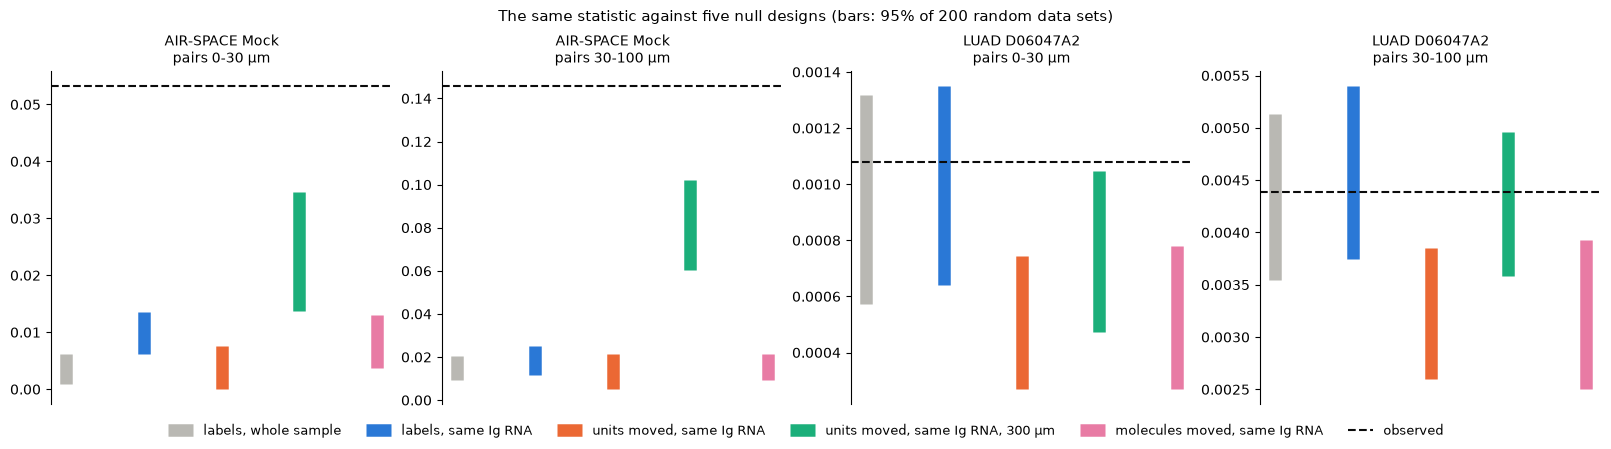

In [10]:
colours = dict(zip(designs(slots_mock), ["#b9b8b3", "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"]))
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), layout="constrained")
for ax, ((data, comp), t) in zip(axes, both.groupby(["data", "component"], sort=False)):
    for k, r in enumerate(t.itertuples()):
        ax.plot([k, k], [r.null_lo, r.null_hi], color=colours[r.design], lw=9, solid_capstyle="butt", label=r.design)
    ax.axhline(t.observed.iloc[0], color="#0b0b0b", lw=1.5, ls="--", label="observed")
    ax.set_xticks([])
    ax.set_title(f"{data}\n{comp}", fontsize=10)
    ax.spines[["top", "right", "bottom"]].set_visible(False)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=6, frameon=False, fontsize=9)
fig.suptitle("The same statistic against five null designs (bars: 95% of 200 random data sets)", fontsize=11)
plt.show()

*Reading the comparison.*

* **Depth.** In the Mock node, same-clone pairs closer than 30 µm are 15.8 times the whole-sample labelling null but
  5.5 times the null that exchanges labels only within Ig RNA strata. The signal is real under both, but two thirds of
  the apparent effect came from mixing Ig-rich and Ig-poor units.
* **Where the units are.** On LUAD, both labelling nulls find nothing (ratios 0.96–1.17, p ≥ 0.23). Moving the cells
  within their Ig RNA stratum instead reports a 2-fold excess with p = 0.005: the IgH-positive cells of this chip sit
  in plasma-cell aggregates, and scattering them over all cells of the same Ig RNA lowers the share of close pairs of
  *any* two IgH-positive cells, same clone or not. The excess is a property of where the cells are, not of their
  clones. Moving units only within 300 µm windows keeps most of that structure and removes the false signal at
  30–100 µm (1.02, p = 0.39); at 0–30 µm a residual excess remains (1.49, p = 0.03), which is what the calls of
  neighbouring cells that share spilled-over RNA give.
* **The conclusion that holds** is the one that survives the null that keeps both confounders: in AIR-SPACE, clones
  are clustered under every design; in LUAD, no clonal clustering is left once positions are kept.

## 5. Whole units, with their read counts

`Relocate(unit=...)` decides what moves together. The default moves every bead with all its records; the last design
above moves single molecules (`unit="molecule"`), so the molecules of one bead, often several molecules of one cell,
land in different places. That random data set is not the observed data set rearranged: it has more and smaller
units than the observed one.

In [11]:
units_after = lambda t: t.drop_duplicates(["spot_id", "clone_id"]).shape[0]
rng = np.random.default_rng(0)
d = designs(slots_mock)
pd.Series({"observed": units_after(air_mock),
           "units moved (unit='spot_id')": units_after(d["units moved, same Ig RNA"](air_mock, rng)),
           "molecules moved (unit='molecule')": units_after(d["molecules moved, same Ig RNA"](air_mock, rng))},
          name="(bead, clone) units in the table")

observed                             459
units moved (unit='spot_id')         459
molecules moved (unit='molecule')    543
Name: (bead, clone) units in the table, dtype: int64

Moving whole beads keeps the 459 (bead, clone) units of the Mock node; moving molecules creates new ones, because
molecules that shared a bead now sit on different beads. The statistic then counts a different number of pairs, and the
null describes data the assay could not have produced (its placebo means differ from the whole-unit design in every
column of the table above). The same holds for read counts: `Relocate` carries every column of a unit, so a statistic
that applies a read floor or a majority vote by reads sees exactly the reads it would see on the observed data. A null
that drew reads afresh, or moved molecules without them, would let large clones win votes by construction.

In [12]:
moved = d["units moved, same Ig RNA"](air_mock, np.random.default_rng(3))
print("read counts identical record by record after the move:",
      bool((moved["consensus_count"].to_numpy() == air_mock["consensus_count"].to_numpy()).all()))

read counts identical record by record after the move: True


## Checklist for a custom placebo

1. Write the statistic as one function of the receptor table, including every filter, collapse and vote.
2. Choose the design from the question: *which label a unit carries* → `Permute` with positions fixed; *where units
   are* → `Relocate` of whole units, with the slots that the assay could really have produced.
3. Put every known confounder into `within=` (Ig RNA depth, section, chain, isotype class) or `window_um=` (local
   neighbourhood), and move whole units (`unit=`), never their parts.
4. Run two or more defensible designs with `nulls.compare_designs`; report the conclusion that holds under all of
   them, and the design under which it does not hold.
5. Fix `rng`, and choose `n_perm` for the smallest p-value you need.

In [13]:
print(f"notebook run time: {time.time() - t_start:.0f} s")

notebook run time: 29 s
